# Telco Customer Churn — Classification
Predict which customers will leave the company (`Churn = 1`).

## 1. Import libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
tele = pd.read_csv('/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv')
tele.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Understand the data

In [3]:
tele.shape

(7043, 21)

In [4]:
tele.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
tele.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


In [6]:
tele.select_dtypes(include='number').columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges'], dtype='object')

In [7]:
tele.select_dtypes(include='object').columns

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges',
       'Churn'],
      dtype='object')

In [8]:
tele.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

In [9]:
tele['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

## 3. Data cleaning
### Drop `customerID`

In [10]:
tele= tele.drop(columns='customerID')

### Fix `TotalCharges` type

In [11]:
tele.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [12]:
tele.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [13]:
tele['TotalCharges'].isna().sum()

np.int64(0)

In [14]:
tele['TotalCharges'].sort_values().head(11)

936      
3826     
4380     
753      
5218     
3331     
6754     
6670     
1340     
488      
1082     
Name: TotalCharges, dtype: object

In [15]:
# pd.to_numeric(tele['TotalCharges'])

In [16]:
tele[tele['TotalCharges'] == ' ']

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [17]:
tele['TotalCharges'] = pd.to_numeric(tele['TotalCharges'], errors='coerce')

In [18]:
tele['TotalCharges'].dtype

dtype('float64')

### Missing values

In [19]:
tele.isna().sum()
tele['TotalCharges']=tele['TotalCharges'].fillna(0)

In [20]:
tele.isna().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### Duplicates

In [21]:
tele.duplicated().sum()

np.int64(22)

### Replace "No internet service" / "No phone service" with "No"

In [22]:
tele.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [23]:
tele['MultipleLines'].value_counts()

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

In [24]:
tele.loc[tele['MultipleLines']=='No phone service','MultipleLines']='No'

In [25]:
tele['MultipleLines'].value_counts()

MultipleLines
No     4072
Yes    2971
Name: count, dtype: int64

In [26]:
for col in tele.select_dtypes('object'):
    print(f'{col} : {tele[col].unique()}')
    print('*'*30)

gender : ['Female' 'Male']
******************************
Partner : ['Yes' 'No']
******************************
Dependents : ['No' 'Yes']
******************************
PhoneService : ['No' 'Yes']
******************************
MultipleLines : ['No' 'Yes']
******************************
InternetService : ['DSL' 'Fiber optic' 'No']
******************************
OnlineSecurity : ['No' 'Yes' 'No internet service']
******************************
OnlineBackup : ['Yes' 'No' 'No internet service']
******************************
DeviceProtection : ['No' 'Yes' 'No internet service']
******************************
TechSupport : ['No' 'Yes' 'No internet service']
******************************
StreamingTV : ['No' 'Yes' 'No internet service']
******************************
StreamingMovies : ['No' 'Yes' 'No internet service']
******************************
Contract : ['Month-to-month' 'One year' 'Two year']
******************************
PaperlessBilling : ['Yes' 'No']
****************************

In [27]:
Change_NO_internet_service= ['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
for col in Change_NO_internet_service:
    tele.loc[tele[col]=='No internet service',col]='No'

In [28]:
for col in Change_NO_internet_service:
    print(f'{col} : {tele[col].value_counts()}')
    print('*'*30)

OnlineSecurity : OnlineSecurity
No     5024
Yes    2019
Name: count, dtype: int64
******************************
OnlineBackup : OnlineBackup
No     4614
Yes    2429
Name: count, dtype: int64
******************************
DeviceProtection : DeviceProtection
No     4621
Yes    2422
Name: count, dtype: int64
******************************
TechSupport : TechSupport
No     4999
Yes    2044
Name: count, dtype: int64
******************************
StreamingTV : StreamingTV
No     4336
Yes    2707
Name: count, dtype: int64
******************************
StreamingMovies : StreamingMovies
No     4311
Yes    2732
Name: count, dtype: int64
******************************


### Outliers

In [29]:
numeric_Cols= tele.select_dtypes(include='number')
numeric_Cols.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76,2279.73
std,0.37,24.56,30.09,2266.79
min,0.00,0.00,18.25,0.00
25%,0.00,9.00,35.50,398.55
50%,0.00,29.00,70.35,1394.55
75%,0.00,55.00,89.85,3786.60
max,1.00,72.00,118.75,8684.80


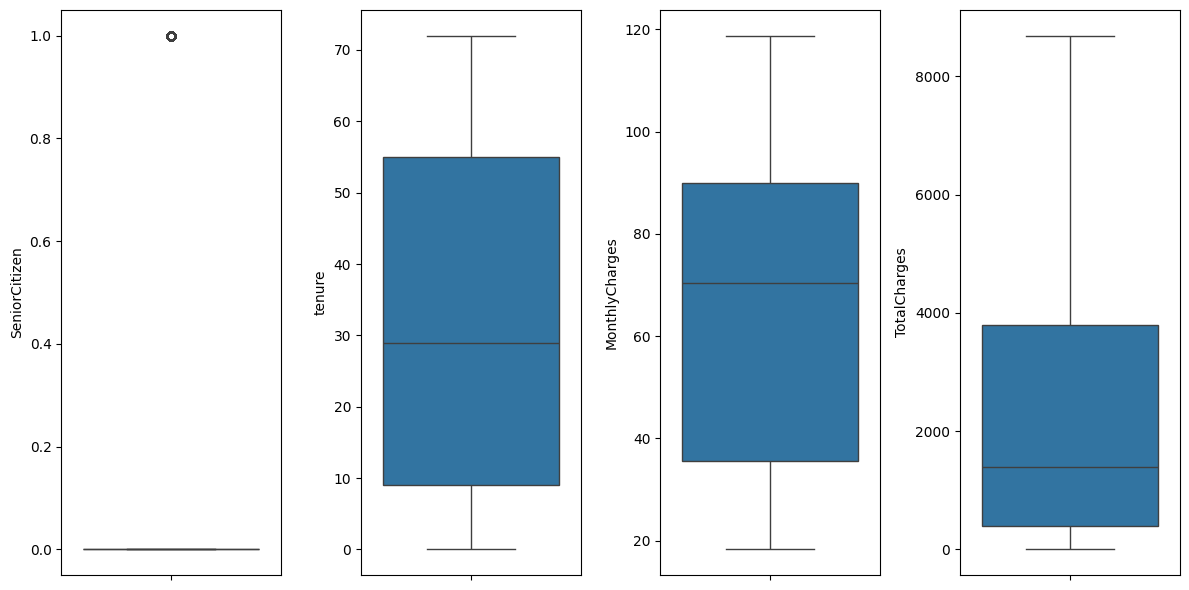

In [30]:
plt.figure(figsize=(12,6))
for i , col in enumerate(numeric_Cols):
    plt.subplot(1,len(numeric_Cols.columns),i+1)
    sns.boxplot(y=col,data=tele)
plt.tight_layout()
plt.show() 

In [31]:
def iqr (col,k=1.5):
    q1=col.quantile(0.25)
    q3=col.quantile(0.75)
    IQR=q3-q1
    lower= q1-k*IQR
    height= q3+k*IQR
    print(f'lower:{lower} .... height:{height} ')

In [32]:
for col in numeric_Cols:
    print(col)
    iqr(tele[col])
    print('*'*30)

SeniorCitizen
lower:0.0 .... height:0.0 
******************************
tenure
lower:-60.0 .... height:124.0 
******************************
MonthlyCharges
lower:-46.02499999999999 .... height:171.375 
******************************
TotalCharges
lower:-4683.525 .... height:8868.675 
******************************


## 4. EDA
### Numeric features vs Churn

In [33]:
for col in numeric_Cols:
    mean= tele.groupby('Churn')[col].mean().round(2)
    print(f'mean:{mean}')

mean:Churn
No     0.13
Yes    0.25
Name: SeniorCitizen, dtype: float64
mean:Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64
mean:Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64
mean:Churn
No     2549.91
Yes    1531.80
Name: TotalCharges, dtype: float64


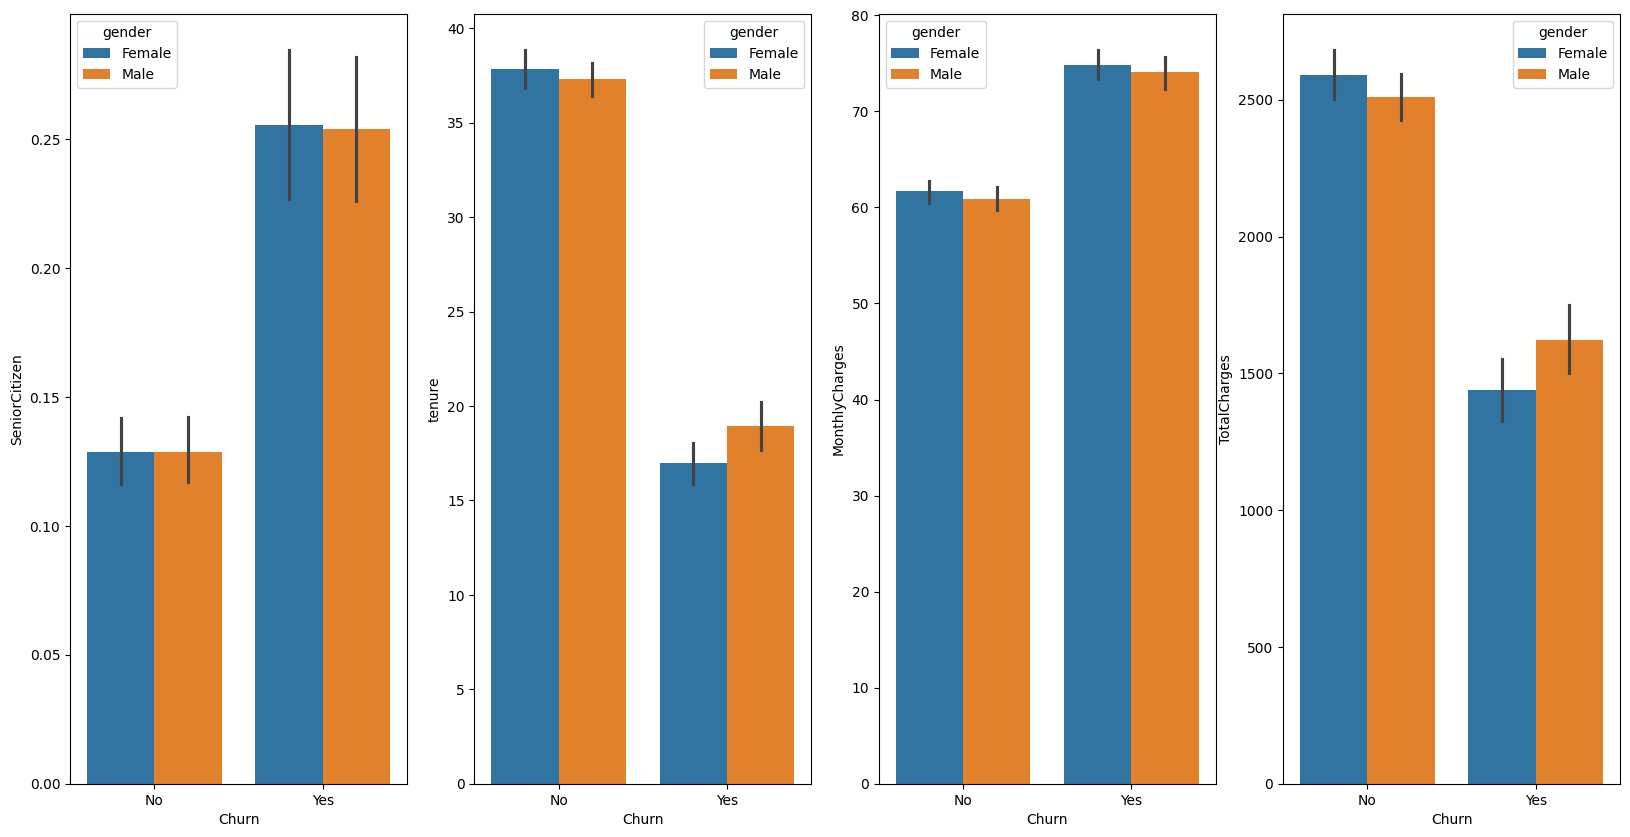

In [34]:
plt.figure(figsize=(20,10))
for i,col in enumerate(numeric_Cols):
    plt.subplot(1,len(numeric_Cols.columns),i+1)
    sns.barplot(x='Churn',y=col,data=tele, hue='gender')
plt.tight_layout
plt.show()

### Categorical features vs Churn

In [35]:
cat_cols=tele.select_dtypes(include='object').drop(columns='Churn')
cat_cols.columns

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

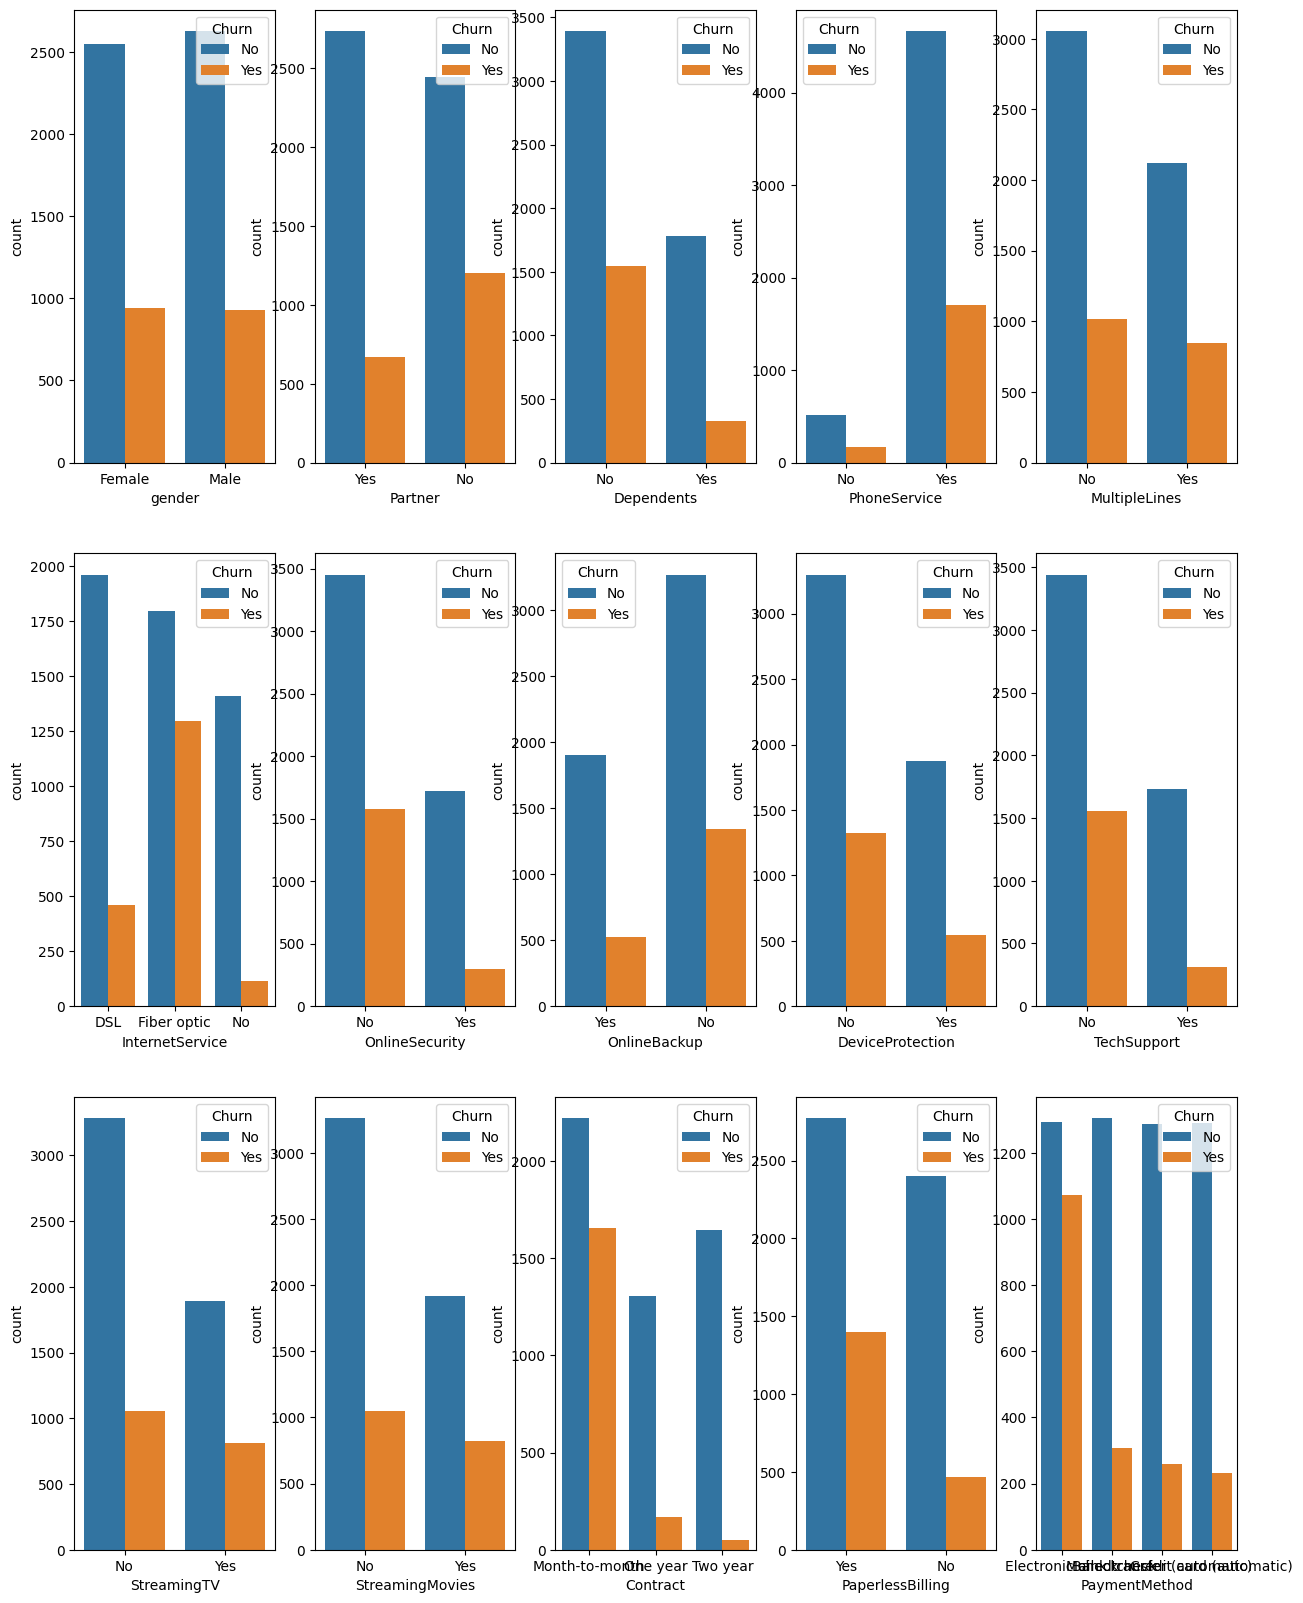

In [36]:
plt.figure(figsize=(15, 20))
for i, col in enumerate(cat_cols):
    plt.subplot(3,5,i+1)
    sns.countplot(x=col, hue='Churn',data=tele)
plt.tight_layout
plt.show()

### Correlation with Churn

In [37]:
Churn_for_Corr= pd.get_dummies(tele['Churn'],dtype=int,drop_first=True,prefix="Churn")

In [38]:
df_Corr = pd.concat([numeric_Cols, Churn_for_Corr], axis=1)

In [39]:
corr= df_Corr.corr()[['Churn_Yes']].sort_values(['Churn_Yes'], ascending=False)
corr

,Churn_Yes
Churn_Yes,1.000000
MonthlyCharges,0.193356
SeniorCitizen,0.150889
TotalCharges,-0.198324
tenure,-0.352229


<Axes: >

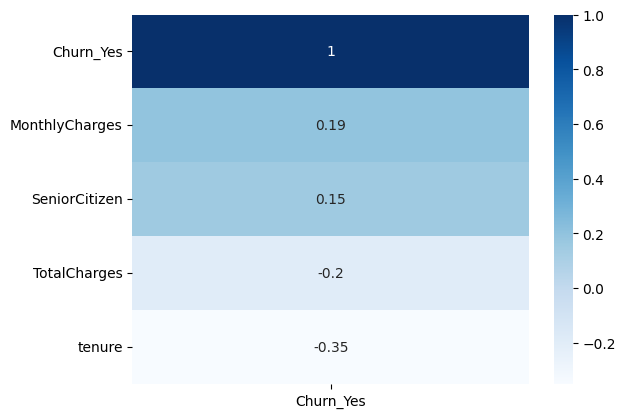

In [40]:
sns.heatmap(corr, annot=True,cmap='Blues')

## 5. Encoding

In [41]:
tele=pd.get_dummies(tele,columns=['Churn'],dtype=int,drop_first=True)
tele.head()


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn_Yes
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [42]:
tele=tele.rename(columns={'Churn_Yes':'Churn'})
tele.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [43]:
cat_cols.columns

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

In [44]:
tele= pd.get_dummies(tele,columns=cat_cols.columns,dtype=int,drop_first=True)

In [45]:
tele.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,...,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,1,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,0,...,1,1,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


## 6. X and y

In [46]:
X=tele.drop(columns='Churn')
y=tele['Churn']

In [47]:
X.shape

(7043, 23)

In [48]:
y.shape

(7043,)

## 7. Train / test split

In [49]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

## 8. Scaling

In [50]:
numeric_Cols.columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')

In [51]:
Scaler_cols=numeric_Cols.drop(columns='SeniorCitizen').columns
from sklearn.preprocessing import StandardScaler , MinMaxScaler , RobustScaler
Scaler=StandardScaler()
X_train[Scaler_cols]=Scaler.fit_transform(X_train[Scaler_cols])
X_test[Scaler_cols]=Scaler.transform(X_test[Scaler_cols])


In [52]:
X_train[Scaler_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5634.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.32,-1.54,-1.01
25%,-0.96,-0.97,-0.83
50%,-0.14,0.18,-0.40
75%,0.92,0.83,0.67
max,1.61,1.79,2.80


## 9. Imbalance

In [53]:
y_train.value_counts()

Churn
0    4139
1    1495
Name: count, dtype: int64

In [54]:
from imblearn.over_sampling import SMOTE,RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
smote = SMOTE(random_state=42)
X_smote,y_smote=smote.fit_resample(X_train,y_train)

In [55]:
y_smote.value_counts()

Churn
0    4139
1    4139
Name: count, dtype: int64

## 10. Final check

In [56]:
X_train.isna().sum().sum()

np.int64(0)

In [57]:
X_train.dtypes

SeniorCitizen                              int64
tenure                                   float64
MonthlyCharges                           float64
TotalCharges                             float64
gender_Male                                int64
Partner_Yes                                int64
Dependents_Yes                             int64
PhoneService_Yes                           int64
MultipleLines_Yes                          int64
InternetService_Fiber optic                int64
InternetService_No                         int64
OnlineSecurity_Yes                         int64
OnlineBackup_Yes                           int64
DeviceProtection_Yes                       int64
TechSupport_Yes                            int64
StreamingTV_Yes                            int64
StreamingMovies_Yes                        int64
Contract_One year                          int64
Contract_Two year                          int64
PaperlessBilling_Yes                       int64
PaymentMethod_Credit

In [58]:
X_train.columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges',
       'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes',
       'MultipleLines_Yes', 'InternetService_Fiber optic',
       'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes',
       'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes',
       'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year',
       'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='object')

## 11. Logistic Regression
### Train the model

In [59]:
from sklearn.linear_model import LogisticRegression
logistic_model=LogisticRegression(max_iter=900)
logistic_model.fit(X_train,y_train)
print(f'Sita0 (b) : {logistic_model.intercept_[0]}')

Sita0 (b) : -1.6314062077887774


### Weights

In [60]:
weights= {}
for name , w in zip (X_train.columns,logistic_model.coef_[0]):
    weights[name]=round(float(w), 2)

In [61]:
weights

{'SeniorCitizen': 0.14,
 'tenure': -1.25,
 'MonthlyCharges': -0.3,
 'TotalCharges': 0.52,
 'gender_Male': 0.02,
 'Partner_Yes': 0.02,
 'Dependents_Yes': -0.23,
 'PhoneService_Yes': -0.36,
 'MultipleLines_Yes': 0.33,
 'InternetService_Fiber optic': 1.05,
 'InternetService_No': -1.05,
 'OnlineSecurity_Yes': -0.37,
 'OnlineBackup_Yes': -0.12,
 'DeviceProtection_Yes': 0.01,
 'TechSupport_Yes': -0.33,
 'StreamingTV_Yes': 0.32,
 'StreamingMovies_Yes': 0.32,
 'Contract_One year': -0.69,
 'Contract_Two year': -1.32,
 'PaperlessBilling_Yes': 0.37,
 'PaymentMethod_Credit card (automatic)': -0.03,
 'PaymentMethod_Electronic check': 0.39,
 'PaymentMethod_Mailed check': 0.07}

### z by hand (for understanding)

In [62]:
Z_by_loop=logistic_model.intercept_[0]
for name , w in weights.items():
    Z_by_loop= Z_by_loop+w*X_test[name]
Z_by_loop

437    -3.043453
2280    0.756495
2235   -2.740200
4460   -0.415992
3761   -3.822435
          ...   
5143   -3.216661
4439   -3.952205
3857   -1.685390
4758   -5.392256
5613   -5.042944
Length: 1409, dtype: float64

### Probabilities

In [63]:
logistic_prob = logistic_model.predict_proba(X_test) # y_prob
logistic_prob

array([[0.9541844 , 0.0458156 ],
       [0.31590535, 0.68409465],
       [0.93925574, 0.06074426],
       ...,
       [0.84383036, 0.15616964],
       [0.99545881, 0.00454119],
       [0.99354394, 0.00645606]])

In [64]:
logistic_prob_one_col= logistic_prob[:,1]
logistic_prob_one_col

array([0.0458156 , 0.68409465, 0.06074426, ..., 0.15616964, 0.00454119,
       0.00645606])

### Predictions (threshold 0.5)

In [65]:
y_pred= logistic_model.predict(X_test)

### Evaluation (threshold 0.5)

In [66]:
from sklearn.metrics import confusion_matrix , classification_report
print(confusion_matrix(y_test, y_pred,labels=[1, 0]))

[[208 166]
 [108 927]]


[[208 166]
 [108 927]]
يعني
            1               0
 1      208 TP(1)      166 FN(0)

 0      108 FP(1)      927 TN(0)


In [67]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



### Threshold 0.3

In [68]:
threshold=0.3
anothr_y_pred_when_threshold3=(logistic_prob_one_col >= 0.3).astype(int)

In [69]:
print(confusion_matrix(y_test, anothr_y_pred_when_threshold3,labels=[1, 0]))

[[283  91]
 [260 775]]


In [70]:
print(classification_report(y_test, anothr_y_pred_when_threshold3))

              precision    recall  f1-score   support

           0       0.89      0.75      0.82      1035
           1       0.52      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.75      0.76      1409



### AUC

In [71]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_test, logistic_prob_one_col)

np.float64(0.8422330724121005)